# v13 — Performance-improvement investigation
Starts from v12 (`Markets_Scorecard_v12.ipynb`, commit `28c5991`). v11/v12 are not modified. Outputs: `output/v13/`.

**Brief:** the v12 FCI-only long-short earns Sharpe 0.68 net of 10 bps in 2017-2026 against a 1.0 minimum / 1.5 preferred objective. Challenge it; do not defend it.

**Discipline**
1. The experiment grid and every decision rule are written to `experiment_registry.json` **before any result in §2-§5 is computed**.
2. Choices use the **discovery window** (returns 2009-06 … 2016-12) or **walk-forward selection** on past data only. The 2017-2026 window is reported but labelled **EXAMINED** — it has been inspected across many iterations and is **not** a fresh holdout.
3. **No untouched out-of-sample period exists in the supplied data.** Genuinely new evidence requires data after 2026-04.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json, subprocess, itertools
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata, norm, skew, kurtosis
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 250; pd.options.display.max_columns = 40; pd.options.display.max_rows = 200
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v13'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']; SEED = 7
print('git HEAD:', subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout.strip())
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', fci=('GSFCI Index', -1),   fx=None, y2='USGGT02Y Index', oas='LF98OAS Index'),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    fci=('BFCIEU Index', +1),  fx=('EURUSD BGN Curncy', 'direct'), y2='GDBR2 Index', oas='LECPOAS Index'),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    fci=('GSGBFCI Index', -1), fx=('GBPUSD BGN Curncy', 'direct'), y2='GUKG2 Index', oas='LC61OAS Index'),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    fci=('GSEAFCI Index', -1), fx=('USDCHF Curncy', 'invert'), y2='GSWISS02 Index', oas='LECPOAS Index'),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    fci=('GSJPFCI Index', -1), fx=('USDJPY BGN Curncy', 'invert'), y2='GJGB2 Index', oas='LJC1OAS Index'),
}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')
RAWX = {c: monthly(pd.read_excel(ROOT/'data'/'raw'/SPEC[c]['file'])) for c in COUNTRIES}
def col(c, k):
    s = SPEC[c]; d = RAWX[c]
    if k == 'fci': return s['fci'][1] * d[s['fci'][0]]
    if k == 'fx': return pd.Series(1.0, index=d.index) if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return d[{'pe': 'BEst P/E Ratio', 'eps': s['eps'], 'y2': s['y2'], 'oas': s['oas']}[k]]
IDX = pd.period_range(max(col(c, 'pe').first_valid_index() for c in COUNTRIES), min(RAWX[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, FCI, FX, Y2, OAS = [pd.DataFrame({c: col(c, k) for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'fci', 'fx', 'y2', 'oas')]
PX = PE * EPS; PX_USD = PX * FX; R = PX_USD.pct_change()             # monthly USD price returns; row t = return EARNED in month t
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
own_sd = lambda d, w=36: d / d.expanding(w).std()
FCI6 = own_sd(FCI - FCI.shift(6)); S0 = cs_z(FCI6)
DISC_R = (pd.Period('2009-06', 'M'), pd.Period('2016-12', 'M')); EXAM_R = (pd.Period('2017-08', 'M'), IDX[-1]); FULL_R = (pd.Period('2009-06', 'M'), IDX[-1])
WINDOWS = {'discovery': DISC_R, 'examined 2017-26': EXAM_R, 'full': FULL_R}
print(f'Panel {IDX[0]}..{IDX[-1]}. Return windows (month the return is earned): ' + ', '.join(f'{k} {a}..{b}' for k, (a, b) in WINDOWS.items()))

git HEAD: 28c5991


Panel 2005-12..2026-04. Return windows (month the return is earned): discovery 2009-06..2016-12, examined 2017-26 2017-08..2026-04, full 2009-06..2026-04


## 1. Audit of the v12 backtest — before changing anything
### 1a. Recompute v12 from its own monthly output, and rebuild it independently

In [2]:
V12 = pd.read_csv(ROOT/'output'/'v12'/'output_backtest_monthly.csv', index_col=0); V12.index = pd.PeriodIndex(V12.index, freq='M')
g12 = V12['Predictive (FCI 6M) | LS gross']; t12 = V12['Predictive (FCI 6M) | LS turnover']
net12 = (g12 - t12 * 10e-4).loc['2017-08':'2026-04']
print(f'v12 L/S net 10 bps 2017-08..2026-04: {len(net12)} monthly returns -> Sharpe {net12.mean() / net12.std() * np.sqrt(12):.3f} (v12 reported 0.678)')
def v12_weights(score, H=6):
    ok = score.notna().all(axis=1); rk = score[ok].rank(axis=1, ascending=False)
    return ((rk <= 2) * 0.5 - (rk >= 4) * 0.5).astype(float).rolling(H, min_periods=1).mean()
W12 = v12_weights(S0)
loop = pd.Series({t: sum(W12.loc[t - 1, c] * R.loc[t, c] for c in COUNTRIES) for t in W12.index[1:]})
print(f'Independent loop Σ w(t-1)·r(t) vs v12 gross: max |diff| = {(loop - g12.reindex(loop.index)).abs().max():.1e}')
AUDIT = [{'item': 'Sharpe formula', 'finding': 'mean / sd of monthly NET returns x sqrt(12), rf = 0, computed on actual monthly portfolio returns', 'verdict': 'Correct for a zero-investment L/S (see 1d for rf and autocorrelation)'},
         {'item': 'Return alignment', 'finding': 'weights at month-end t earn the month t+1 USD return; independent loop matches to machine precision', 'verdict': 'Correct; no look-ahead'}]

v12 L/S net 10 bps 2017-08..2026-04: 105 monthly returns -> Sharpe 0.678 (v12 reported 0.678)
Independent loop Σ w(t-1)·r(t) vs v12 gross: max |diff| = 9.8e-17


### 1b. Weights and exposure — the overlapping tranches NET against each other

In [3]:
gross = W12.abs().sum(axis=1); longs = W12.clip(lower=0).sum(axis=1); shorts = W12.clip(upper=0).sum(axis=1)
EXPO = pd.DataFrame({'gross exposure': gross, 'long leg': longs, 'short leg': shorts, 'net': W12.sum(axis=1)}).loc['2009-10':]
display(EXPO.describe().T[['mean', 'min', '25%', '50%', 'max']])
print(f'Target portfolio gross = 2.0 (+100% / -100%). The HELD book (average of 6 tranches) has mean gross {gross.loc["2009-10":].mean():.2f}: '
      'a market that is long in one tranche and short in another nets to ~0. The book runs at ~'
      f'{gross.loc["2009-10":].mean() / 2:.0%} of the intended exposure, varying month to month.')
AUDIT.append({'item': 'Long / short weights', 'finding': f'+50% x2 / -50% x2 per tranche; held book gross averages {gross.loc["2009-10":].mean():.2f} (range {gross.loc["2009-10":].min():.2f}-{gross.loc["2009-10":].max():.2f}); net exposure 0',
              'verdict': 'As specified, but tranche netting means exposure is lower and time-varying. Sharpe is scale-free only if exposure is constant.'})

,mean,min,25%,50%,max
gross exposure,1.482,0.500,1.167,1.500,2.000
long leg,0.741,0.250,0.583,0.750,1.000
short leg,-0.741,-1.000,-0.917,-0.750,-0.250
net,0.000,-0.000,-0.000,0.000,0.000


Target portfolio gross = 2.0 (+100% / -100%). The HELD book (average of 6 tranches) has mean gross 1.48: a market that is long in one tranche and short in another nets to ~0. The book runs at ~74% of the intended exposure, varying month to month.


### 1c. Drift-accurate engine vs the v12 constant-weight approximation
v12 averaged target weights and charged costs on the change of that average. A real book lets positions **drift** with prices between trades, and the drift itself has to be traded back. The engine below carries every tranche explicitly as a fraction of NAV, drifts it monthly, expires it after H months, and charges cost on the actual traded quantity (new aggregate − drifted aggregate), both legs.

In [4]:
RV = R.to_numpy(float); T_ = len(IDX)
COV36 = {i: np.cov(RV[i - 35:i + 1].T) for i in range(36, T_) if not np.isnan(RV[i - 35:i + 1]).any()}
VOL36 = {i: np.sqrt(np.diag(c)) for i, c in COV36.items()}
def simulate(target, H, step=1, offset=0, start=None):
    """target(i) -> weight vector (fraction of NAV) formed at month-end i, or None. Returns gross return, turnover, held weights (pre-trade drift handled)."""
    i0 = next(i for i in range(T_) if target(i) is not None and (start is None or IDX[i] >= start))
    tr = []                                                    # list of [age, weights(np)]
    gret, turn, held = np.full(T_, np.nan), np.full(T_, np.nan), np.full((T_, 5), np.nan)
    frac = step / H
    for i in range(i0, T_):
        agg_pre = sum((w for _, w in tr), np.zeros(5))         # drifted aggregate before trading at month-end i
        tr = [[a + 1, w] for a, w in tr]; tr = [[a, w] for a, w in tr if a < H]   # expire
        if i == i0:
            w0 = target(i)
            if step == 1: tr = [[k, w0 * frac] for k in range(H)]
            else: tr = [[(i - offset) % H, w0 * frac]]
        elif (i - offset) % step == 0:
            w = target(i)
            if w is not None: tr.append([0, w * frac])
        agg = sum((w for _, w in tr), np.zeros(5)); held[i] = agg
        turn[i] = np.abs(agg - agg_pre).sum()
        if i + 1 < T_:
            r = RV[i + 1]; rp = float(agg @ r); gret[i + 1] = rp
            tr = [[a, w * (1 + r) / (1 + rp)] for a, w in tr]     # drift, re-expressed as fraction of the new NAV
    idx = IDX
    return pd.Series(gret, idx), pd.Series(turn, idx).shift(1), pd.DataFrame(held, idx, COUNTRIES)   # cost of trade at i paid in i+1
def rankw(z, kind):
    rk = rankdata(-z)                                           # 1 = most attractive
    if kind == 'LS2': return np.where(rk <= 2, .5, np.where(rk >= 4, -.5, 0.))
    if kind == 'LS1': return np.where(rk == 1, 1., np.where(rk == 5, -1., 0.))
    if kind == 'LO2': return np.where(rk <= 2, .5, 0.)
    if kind == 'LO1': return np.where(rk == 1, 1., 0.)
    raise ValueError
S0V = S0.to_numpy(float)
base_t = lambda i: None if np.isnan(S0V[i]).any() else rankw(S0V[i], 'LS2')
g_d, t_d, h_d = simulate(base_t, 6)
def perf(r, tn=None, bps=0, w=None):
    if w is not None: m = (r.index >= w[0]) & (r.index <= w[1]); r = r[m]; tn = tn[m] if tn is not None else None
    net = r - (tn * bps * 1e-4 if tn is not None else 0); net = net.dropna(); cum = (1 + net).cumprod()
    return {'Net return % p.a.': (cum.iloc[-1] ** (12 / len(net)) - 1) * 100, 'Vol % p.a.': net.std() * np.sqrt(12) * 100,
            'Sharpe': net.mean() / net.std() * np.sqrt(12), 'Max DD %': (cum / cum.cummax() - 1).min() * 100,
            'Turnover p.a. (x)': (tn.mean() * 12) if tn is not None else 0., 'months': len(net)}
rows = []
for nm, (g, tn) in {'v12 constant-weight approximation': (g12.reindex(IDX), t12.reindex(IDX)), 'drift-accurate engine (same rules)': (g_d, t_d)}.items():
    for wl, w in WINDOWS.items():
        for bps in (0, 10):
            rows.append({'engine': nm, 'window': wl, 'cost bps': bps, **perf(g, tn, bps, w)})
ENG = pd.DataFrame(rows).set_index(['engine', 'window', 'cost bps']); display(ENG)
ENG.to_csv(OUT/'audit_engine_comparison.csv')
AUDIT.append({'item': 'Rebalancing / tranche accounting', 'finding': 'v12 used the average of target weights (positions re-weighted monthly, drift ignored). Drift-accurate engine changes Sharpe by the amounts in audit_engine_comparison.csv',
              'verdict': 'Approximation acceptable if the two agree; v13 uses the drift-accurate engine throughout'})
AUDIT.append({'item': 'Transaction costs', 'finding': 'one-way bps x Σ|Δw| over all five markets: both long and short legs charged; first build charged; v12 omitted drift-induced re-trading',
              'verdict': 'Correct in principle; drift turnover now included'})

Net return % p.a.  Vol % p.a.  Sharpe  Max DD %  Turnover p.a. (x)  months
engine                             window           cost bps                                                                            
v12 constant-weight approximation  discovery        0                     4.338       5.693   0.775   -11.501              4.782      91
                                                    10                    3.841       5.709   0.689   -11.933              4.782      91
                                   examined 2017-26 0                     3.992       5.299   0.766    -8.738              4.610     105
                                                    10                    3.514       5.307   0.678    -9.369              4.610     105
                                   full             0                     3.928       5.397   0.742   -11.501              4.765     203
                                                    10                    3.435       5.409   0.652   -11.933              4.765     203
drift-accurate engine (same rules) discovery        0                     4.495       5.748   0.795   -11.968              4.785      91
                                                    10                    3.997       5.769   0.709   -12.443              4.785      91
                                   examined 2017-26 0                     3.985       5.243   0.772    -9.152              4.800     105
                                                    10                    3.488       5.253   0.680    -9.647              4.800     105
                                   full             0                     3.990       5.395   0.753   -11.968              4.874     203
                                                    10                    3.485       5.411   0.661   -12.443              4.874     203

### 1d. Annualisation, risk-free rate and benchmark

In [5]:
net_b = (g_d - t_d * 10e-4).loc[EXAM_R[0]:EXAM_R[1]].dropna()
ac = [net_b.autocorr(k) for k in range(1, 12)]
sr_m = net_b.mean() / net_b.std(); sr_naive = sr_m * np.sqrt(12)
sr_lo = sr_m * 12 / np.sqrt(12 + 2 * sum((12 - k) * ac[k - 1] for k in range(1, 12)))     # Lo (2002) adjustment
print('Autocorrelation of monthly net L/S returns, lags 1-6:', np.round(ac[:6], 2))
print(f'Sharpe sqrt(12) annualisation {sr_naive:.3f} vs Lo (2002) autocorrelation-adjusted {sr_lo:.3f}')
# long-only: rf proxy
rf = (Y2['US'] / 100 / 12).shift(1)                          # US 2Y yield as a cash proxy (no T-bill series supplied) - labelled proxy
lo2 = lambda i: None if np.isnan(S0V[i]).any() else rankw(S0V[i], 'LO2')
g_lo, t_lo, _ = simulate(lo2, 6)
ew_g, _, _ = simulate(lambda i: np.full(5, .2), 1)
m = (g_lo.index >= EXAM_R[0]); x = (g_lo - t_lo * 10e-4)[m].dropna()
print(f'Long-only top-2 (examined, 10 bps): Sharpe rf=0 {x.mean()/x.std()*np.sqrt(12):.2f} | excess of US 2Y proxy {(x - rf.reindex(x.index)).mean()/x.std()*np.sqrt(12):.2f} '
      f'| information ratio vs EW {((x - ew_g.reindex(x.index)).mean() / (x - ew_g.reindex(x.index)).std() * np.sqrt(12)):.2f}')
AUDIT.append({'item': 'Annualisation', 'finding': f'monthly Sharpe x sqrt(12) = {sr_naive:.2f}; Lo-adjusted for autocorrelation = {sr_lo:.2f}', 'verdict': f'sqrt(12) is mildly flattering here (Lo-adjusted {sr_lo:.2f} vs {sr_naive:.2f}, driven by positive lag-3/4 autocorrelation from overlapping tranches); both are reported'})
AUDIT.append({'item': 'Risk-free rate', 'finding': 'L/S is self-financing: rf=0 is correct (collateral interest is not strategy alpha). Long-only ABSOLUTE Sharpe should use excess returns: no T-bill series supplied; US 2Y used as a disclosed proxy',
              'verdict': 'L/S fine. Long-only should be judged by information ratio vs EW, which needs no rf'})
AUDIT.append({'item': 'Benchmark', 'finding': 'equal-weight 5 markets (USD, price return). No market-cap data supplied, so a cap-weighted DM benchmark (US ~70%) cannot be built',
              'verdict': 'EW is consistent with a relative-ranking objective; disclosed'})

Autocorrelation of monthly net L/S returns, lags 1-6: [ 0.09 -0.16  0.15  0.18 -0.04 -0.1 ]
Sharpe sqrt(12) annualisation 0.680 vs Lo (2002) autocorrelation-adjusted 0.598
Long-only top-2 (examined, 10 bps): Sharpe rf=0 0.65 | excess of US 2Y proxy 0.62 | information ratio vs EW 0.63


### 1e. Which countries drive return, volatility and drawdown? (baseline: top-2/bottom-2, 6M tranches, 10 bps)

In [6]:
pnl = (h_d.shift(1) * R).loc[FULL_R[0]:FULL_R[1]]; port = g_d.loc[FULL_R[0]:FULL_R[1]]
rows = []
for wl, (a, b) in WINDOWS.items():
    P = pnl.loc[a:b]; p = port.loc[a:b]
    cum = (1 + p).cumprod(); trough = (cum / cum.cummax() - 1).idxmin(); peak = cum.loc[:trough].idxmax()
    for c in COUNTRIES:
        rows.append({'window': wl, 'country': c, 'return contrib % p.a.': P[c].mean() * 1200,
                     'share of variance %': P[c].cov(p) / p.var() * 100, 'avg weight %': h_d.shift(1).loc[a:b, c].mean() * 100,
                     '% months long': (h_d.shift(1).loc[a:b, c] > 0.01).mean() * 100, '% months short': (h_d.shift(1).loc[a:b, c] < -0.01).mean() * 100,
                     f'max-DD contrib % (peak→trough)': P.loc[peak:trough, c].sum() * 100, 'DD window': f'{peak}→{trough}'})
CTRY = pd.DataFrame(rows).set_index(['window', 'country']); display(CTRY)
CTRY.to_csv(OUT/'audit_country_contribution.csv')
pd.DataFrame(AUDIT).to_csv(OUT/'audit_backtest_checks.csv', index=False); display(pd.DataFrame(AUDIT))

return contrib % p.a.  share of variance %  avg weight %  % months long  % months short  max-DD contrib % (peak→trough)        DD window
window           country                                                                                                                                              
discovery        US                           0.226               12.488        -0.038         43.956          49.451                          -6.187  2013-04→2014-04
                 Eurozone                     3.402               29.919        -4.878         32.967          62.637                          -1.316  2013-04→2014-04
                 UK                           0.618                8.316        -1.012         50.549          49.451                           0.892  2013-04→2014-04
                 Switzerland                  0.946               15.934         5.601         53.846          43.956                          -3.718  2013-04→2014-04
                 Japan                       -0.624               33.343         1.120         46.154          49.451                           0.563  2013-04→2014-04
examined 2017-26 US                           2.294               27.150        11.319         60.952          31.429                          -5.437  2025-02→2025-12
                 Eurozone                     2.652               29.789         0.256         46.667          47.619                           3.011  2025-02→2025-12
                 UK                           0.213               16.290       -11.957         30.476          63.810                           1.772  2025-02→2025-12
                 Switzerland                 -0.938                4.789        -4.952         44.762          55.238                           0.302  2025-02→2025-12
                 Japan                       -0.172               21.981         6.073         55.238          33.333                          -7.922  2025-02→2025-12
full             US                           1.176               19.692         4.933         51.232          41.379                          -6.187  2013-04→2014-04
                 Eurozone                     2.698               30.199        -2.750         38.916          56.158                          -1.316  2013-04→2014-04
                 UK                           0.556               11.746        -5.660         41.872          55.172                           0.892  2013-04→2014-04
                 Switzerland                 -0.112               10.716        -0.146         48.768          50.246                          -3.718  2013-04→2014-04
                 Japan                       -0.255               27.648         4.340         51.724          39.901                           0.563  2013-04→2014-04

,item,finding,verdict
0,Sharpe formula,"mean / sd of monthly NET returns x sqrt(12), r...",Correct for a zero-investment L/S (see 1d for ...
1,Return alignment,weights at month-end t earn the month t+1 USD ...,Correct; no look-ahead
2,Long / short weights,+50% x2 / -50% x2 per tranche; held book gross...,"As specified, but tranche netting means exposu..."
3,Rebalancing / tranche accounting,v12 used the average of target weights (positi...,Approximation acceptable if the two agree; v13...
4,Transaction costs,one-way bps x Σ|Δw| over all five markets: bot...,Correct in principle; drift turnover now included
5,Annualisation,monthly Sharpe x sqrt(12) = 0.68; Lo-adjusted ...,sqrt(12) is mildly flattering here (Lo-adjuste...
6,Risk-free rate,L/S is self-financing: rf=0 is correct (collat...,L/S fine. Long-only should be judged by inform...
7,Benchmark,"equal-weight 5 markets (USD, price return). No...",EW is consistent with a relative-ranking objec...


## 2. Experiment registry — written BEFORE any result below is computed
Every specification tested in §3-§5 is listed here with its rationale, together with the decision rules. Nothing is added after results are seen; anything that was would be logged as an amendment.

In [7]:
CONSTRUCTIONS = {
 'C1 LS top1-bottom1':        'Concentrate on the strongest and weakest signal; higher conviction, less diversification',
 'C2 LS top2-bottom2':        'Baseline (v7-v12)',
 'C3 LO top1':                'Long-only, single most attractive market vs EW',
 'C4 LO top2':                'Long-only, two most attractive markets vs EW (v12 long-only)',
 'C5 LS rank-weighted':       'Use the whole ranking: weights ∝ centred rank (2,1,0,-1,-2)/3, gross 2',
 'C6 LS z-weighted':          'Continuous: weights ∝ cross-sectional z, gross 2 (score weighting was weak in v7 - retested on FCI)',
 'C7 LS top2-bottom2 inv-vol':'Volatility-adjusted sizing: within each leg weight ∝ 1/σ (trailing 36M), each leg gross 1',
 'C8 LS top2-bottom2 ERC':    'Risk-balanced across countries: equal risk contribution of the 4 signed positions (trailing 36M covariance), gross 2',
 'C9 LS top2-bottom2 vol-tgt':'Baseline scaled to 10% ex-ante vol (trailing 36M covariance), leverage cap 3x',
}
SCHEDULES = {'monthly': dict(H=1, step=1, offsets=[0]), 'quarterly (discrete)': dict(H=3, step=3, offsets=[0, 1, 2]),
             'six-monthly (discrete)': dict(H=6, step=6, offsets=list(range(6))), '3M overlapping tranches': dict(H=3, step=1, offsets=[0]),
             '6M overlapping tranches': dict(H=6, step=1, offsets=[0])}
SIGNALS = {
 'S0 base: 6M chg / expanding sd':        'v12 predictive signal',
 'S1 lookback 3M':                        'faster reaction to financing shocks',
 'S2 lookback 9M':                        'slower, less noisy',
 'S3 lookback 12M':                       'annual change; slowest',
 'S4 rolling 36M sd scaling':             'standardise by RECENT volatility instead of full history',
 'S5 own z-score (expanding mean & sd)':   'country-level normalisation removing each FCI\'s own drift',
 'S6 absolute change, cross-sectional z':  'no country-level scaling: absolute index-point changes (mixed units - BFCIEU differs)',
 'S7 FCI level, own z (60M)':             'state rather than change: easy vs tight relative to own history',
 'S8 3M moving average of S0 input':      'smoothing to cut turnover from noisy month-to-month changes',
 'S9 blend of 3/6/12M lookbacks':         'ensemble across horizons to reduce parameter dependence',
 'S10 hysteresis (enter rank<=2, exit rank>=4)':'persistence filter: hold a position until the signal clearly reverses',
 'S11 threshold |z|>=0.5':                'only take positions where the signal is clearly away from the average',
 'S12 absolute confirmation':             'long only if own FCI is actually easing (>0), short only if actually tightening (<0)',
 'E1 FCI + EPS (equal weight)':           'portfolio-level test of adding EPS revisions',
}
EXPLORATORY = {'X1 ERP vs credit, own z 36/60/120M': 'discovery-only sensitivity', 'X2 trend R2 12M unsigned (as v10)': 'discovery-only',
               'X3 trend R2 12M SIGNED = sign(slope) x R2 (pre-registered fix)': 'discovery-only', 'X4 signed trend R2 6M/24M': 'discovery-only sensitivity'}
RULES = {
 'costs': [0, 5, 10, 20], 'primary cost for decisions': 10,
 'portfolio choice (Rule P)': 'Among 45 construction x schedule configs on signal S0: highest DISCOVERY net Sharpe at 10 bps, subject to discovery net Sharpe at 20 bps > 0, turnover <= 8x p.a. and no single country contributing > 60% of discovery return. Discrete schedules use the mean across start offsets.',
 'signal choice (Rule S)': 'Replace S0 only if a variant (on the baseline C2 + 6M tranches) beats S0 by >= 0.20 DISCOVERY net Sharpe at 10 bps AND has discovery 6M IC >= S0. Otherwise keep S0.',
 'EPS (Rule E)': 'Add EPS only if FCI+EPS minus FCI-only paired monthly net return in DISCOVERY has block-bootstrap p < 0.10 (one-sided) on the Rule-P construction.',
 'walk-forward': 'Each January from 2013, pick the config with the best expanding-window net Sharpe (10 bps, >= 36 months of its history), hold it for 12 months; report the stitched return (switching costs between configs ignored - disclosed).',
 'exploratory': 'Evaluated on DISCOVERY only for promotion purposes. Examined-window numbers shown, labelled CONTAMINATED, and never used for a decision. No promotion in v13 regardless of outcome: independent evaluation requires post-2026-04 data.',
 'reporting': 'Every config and cost reported in CSV. Examined window = 2017-08..2026-04, NOT a fresh holdout.',
}
REG = {'created_before_results': True, 'constructions': CONSTRUCTIONS, 'schedules': {k: {kk: vv for kk, vv in v.items()} for k, v in SCHEDULES.items()},
       'signals': SIGNALS, 'exploratory': EXPLORATORY, 'rules': RULES, 'windows': {k: [str(a), str(b)] for k, (a, b) in WINDOWS.items()},
       'n_portfolio_configs': len(CONSTRUCTIONS) * len(SCHEDULES), 'n_signal_specs': len(SIGNALS), 'n_exploratory': len(EXPLORATORY)}
json.dump(REG, open(OUT/'experiment_registry.json', 'w'), indent=2)
# amendments made after a run are appended to the registry at the end of the notebook (§9)
print(f"Registry written: {REG['n_portfolio_configs']} portfolio configs, {REG['n_signal_specs']} signal specs, {REG['n_exploratory']} exploratory specs, 4 cost levels.")

Registry written: 45 portfolio configs, 14 signal specs, 4 exploratory specs, 4 cost levels.


## 3. Portfolio construction (signal fixed at S0)

In [8]:
from scipy.optimize import minimize
def erc(cov):
    """Equal risk contribution via the convex Spinu (2013) formulation: min 0.5 x'Cx - (1/n) sum log x, x > 0.
    Unique solution even when signed positions hedge each other (negative covariances)."""
    n = len(cov); c = cov / np.mean(np.diag(cov))
    f = lambda x: 0.5 * x @ c @ x - np.log(x).sum() / n
    gfun = lambda x: c @ x - 1 / (n * x)
    x = minimize(f, np.ones(n) / np.sqrt(np.diag(c)) / n, jac=gfun, bounds=[(1e-9, None)] * n, method='L-BFGS-B').x
    rc = x * (c @ x); assert rc.min() > 0 and rc.max() / rc.min() < 1.01, rc
    return x / x.sum()
AMEND = [{'amendment': 'C8 ERC solver', 'when': 'after first grid run', 'what': 'replaced a fixed-point iteration that diverged when signed positions had negative covariance (C8 vol 17-26% vs ~6-8% for every other L/S) with the convex Spinu formulation; equal risk contributions now asserted to within 1%',
          'spec changed?': 'No - same definition (equal risk contribution, gross 2); bug fix only'}]
def make_target(S, cname):
    SV = S.to_numpy(float)
    def f(i):
        z = SV[i]
        if np.isnan(z).any(): return None
        if cname.startswith('C1'): return rankw(z, 'LS1')
        if cname.startswith('C2'): return rankw(z, 'LS2')
        if cname.startswith('C3'): return rankw(z, 'LO1')
        if cname.startswith('C4'): return rankw(z, 'LO2')
        if cname.startswith('C5'): return (3 - rankdata(-z)) / 3
        if cname.startswith('C6'): return z / np.abs(z).sum() * 2
        if i not in COV36: return None
        w = rankw(z, 'LS2'); s = np.sign(w); sel = s != 0
        if cname.startswith('C7'):
            iv = np.where(sel, 1 / VOL36[i], 0); out = np.zeros(5)
            for sg in (1, -1): m = s == sg; out[m] = sg * iv[m] / iv[m].sum()
            return out
        if cname.startswith('C8'):
            idx = np.where(sel)[0]; cy = COV36[i][np.ix_(idx, idx)] * np.outer(s[idx], s[idx]); x = erc(cy)
            out = np.zeros(5); out[idx] = s[idx] * x * 2; return out
        if cname.startswith('C9'):
            vol = np.sqrt(w @ COV36[i] @ w * 12); return w * min(3.0, 0.10 / vol)
    return f
def run_config(S, cname, sched):
    sp = SCHEDULES[sched]; outs = []
    for off in sp['offsets']:
        g, tn, h = simulate(make_target(S, cname), sp['H'], sp['step'], off, start=pd.Period('2009-05', 'M'))
        outs.append((g, tn, h))
    return outs
def is_lo(c): return c.startswith(('C3', 'C4'))
EWG = ew_g
def book_returns(cname, outs, bps):
    """net return series per offset; long-only judged ACTIVE vs EW (cost-free benchmark)"""
    res = []
    for g, tn, h in outs:
        net = g - tn * bps * 1e-4
        res.append(net - EWG if is_lo(cname) else net)
    return res
def summarise(series_list, tn_list, w):
    ps = [perf(s, None, 0, w) for s in series_list]
    d = {k: np.mean([p[k] for p in ps]) for k in ps[0]}
    d['Sharpe min over offsets'] = min(p['Sharpe'] for p in ps); d['Sharpe max over offsets'] = max(p['Sharpe'] for p in ps)
    m = lambda s: s[(s.index >= w[0]) & (s.index <= w[1])]
    d['Turnover p.a. (x)'] = np.mean([m(t).mean() * 12 for t in tn_list])
    return d
RUNS = {}; rows = []
for cname in CONSTRUCTIONS:
    for sched in SCHEDULES:
        outs = run_config(S0, cname, sched); RUNS[(cname, sched)] = outs
        for bps in RULES['costs']:
            sl = book_returns(cname, outs, bps)
            for wl, w in WINDOWS.items():
                rows.append({'construction': cname, 'schedule': sched, 'cost bps': bps, 'window': wl, 'basis': 'active vs EW' if is_lo(cname) else 'long-short',
                             **summarise(sl, [o[1] for o in outs], w)})
PC = pd.DataFrame(rows).set_index(['construction', 'schedule', 'cost bps', 'window'])
PC.to_csv(OUT/'portfolio_construction_grid.csv')
show = PC.xs(10, level='cost bps')[['Sharpe', 'Net return % p.a.', 'Vol % p.a.', 'Max DD %', 'Turnover p.a. (x)']].unstack('window')
show.columns = [f'{a} | {b}' for a, b in show.columns]
display(show[[c for c in show.columns if 'Sharpe' in c] + [c for c in show.columns if 'Max DD' in c] + [c for c in show.columns if 'Turnover' in c and 'full' in c]].round(2))

Sharpe | discovery  Sharpe | examined 2017-26  Sharpe | full  Max DD % | discovery  Max DD % | examined 2017-26  Max DD % | full  Turnover p.a. (x) | full
construction               schedule                                                                                                                                                                           
C1 LS top1-bottom1         3M overlapping tranches               0.200                      0.440          0.290               -22.170                      -19.290          -26.190                     9.820
                           6M overlapping tranches               0.150                      0.540          0.320               -19.950                      -15.480          -19.950                     6.290
                           monthly                               0.180                      0.010          0.070               -20.120                      -26.680          -36.510                    17.560
                           quarterly (discrete)                  0.190                      0.360          0.250               -23.080                      -20.720          -28.970                     9.830
                           six-monthly (discrete)                0.130                      0.340          0.230               -24.700                      -25.210          -29.530                     6.310
C2 LS top2-bottom2         3M overlapping tranches               0.630                      0.440          0.490               -10.930                      -13.540          -13.900                     6.920
                           6M overlapping tranches               0.710                      0.680          0.660               -12.440                       -9.650          -12.440                     4.870
                           monthly                               0.180                      0.160          0.140               -14.410                      -14.110          -20.350                    12.990
                           quarterly (discrete)                  0.520                      0.360          0.400               -14.750                      -15.540          -18.150                     6.920
                           six-monthly (discrete)                0.530                      0.450          0.460               -16.660                      -17.950          -21.220                     4.880
C3 LO top1                 3M overlapping tranches               0.270                      0.460          0.300               -16.310                       -6.820          -23.790                     4.960
                           6M overlapping tranches               0.330                      0.230          0.240               -13.160                      -11.380          -14.370                     2.960
                           monthly                               0.090                     -0.000          0.010               -19.220                      -17.370          -32.800                     8.570
                           quarterly (discrete)                  0.250                      0.340          0.250               -17.180                      -13.190          -25.750                     4.950
                           six-monthly (discrete)                0.260                      0.140          0.160               -16.940                      -18.520          -23.400                     2.960
C4 LO top2                 3M overlapping tranches               0.710                      0.530          0.560                -7.220                       -6.510           -7.220                     3.300
                           6M overlapping tranches               0.720                      0.630          0.620                -7.140                       -4.310           -7.140                     2.370
                           monthly                               0.210                      0.200          0.170       

### 3a. Rule P — choose on DISCOVERY only, with the pre-registered constraints

In [9]:
def contrib_share(cname, outs, w):
    g, tn, h = outs[0]; act = h.shift(1) - (0.2 if is_lo(cname) else 0)
    P = (act * R).loc[w[0]:w[1]]; c = P.mean() * 1200
    return c, (c.max() / c.sum()) if c.sum() > 0 else np.nan
rows = []
for (cname, sched), outs in RUNS.items():
    d10 = PC.loc[(cname, sched, 10, 'discovery')]; d20 = PC.loc[(cname, sched, 20, 'discovery')]
    c, sh = contrib_share(cname, outs, DISC_R)
    rows.append({'construction': cname, 'schedule': sched, 'disc Sharpe 10bps': d10['Sharpe'], 'disc Sharpe 20bps': d20['Sharpe'],
                 'disc turnover': d10['Turnover p.a. (x)'], 'largest country share of disc return': sh, 'largest contributor': c.idxmax(),
                 'passes 20bps>0': d20['Sharpe'] > 0, 'passes turnover<=8': d10['Turnover p.a. (x)'] <= 8, 'passes country<=60%': (sh <= .6) if pd.notna(sh) else False,
                 'EXAMINED Sharpe 10bps (not used)': PC.loc[(cname, sched, 10, 'examined 2017-26'), 'Sharpe']})
RP = pd.DataFrame(rows).set_index(['construction', 'schedule'])
RP['eligible'] = RP[['passes 20bps>0', 'passes turnover<=8', 'passes country<=60%']].all(axis=1)
RP = RP.sort_values('disc Sharpe 10bps', ascending=False); display(RP.head(15))
RP.to_csv(OUT/'rule_P_selection.csv')
elig = RP[RP.eligible]
PICK_P = elig.index[0] if len(elig) else None
print('Rule P pick:', PICK_P, '| top discovery config overall:', RP.index[0], f"(largest-country share {RP.iloc[0]['largest country share of disc return']:.0%})")

,,disc Sharpe 10bps,disc Sharpe 20bps,disc turnover,largest country share of disc return,largest contributor,passes 20bps>0,passes turnover<=8,passes country<=60%,EXAMINED Sharpe 10bps (not used),eligible
construction,schedule,,,,,,,,,,
C4 LO top2,6M overlapping tranches,0.724,0.652,2.268,0.659,Eurozone,True,True,False,0.626,False
C8 LS top2-bottom2 ERC,6M overlapping tranches,0.717,0.619,4.987,0.844,Eurozone,True,True,False,0.488,False
C2 LS top2-bottom2,6M overlapping tranches,0.709,0.624,4.785,0.745,Eurozone,True,True,False,0.680,False
C4 LO top2,3M overlapping tranches,0.708,0.624,2.909,0.795,Eurozone,True,True,False,0.535,False
C9 LS top2-bottom2 vol-tgt,6M overlapping tranches,0.699,0.613,5.941,0.714,Eurozone,True,True,False,0.707,False
C8 LS top2-bottom2 ERC,3M overlapping tranches,0.668,0.540,7.009,0.868,Eurozone,True,True,False,0.330,False
C7 LS top2-bottom2 inv-vol,6M overlapping tranches,0.646,0.564,4.788,0.657,Eurozone,True,True,False,0.672,False
C9 LS top2-bottom2 vol-tgt,3M overlapping tranches,0.639,0.529,8.479,0.732,Eurozone,True,False,False,0.459,False
C2 LS top2-bottom2,3M overlapping tranches,0.632,0.524,6.629,0.789,Eurozone,True,True,False,0.444,False


Rule P pick: ('C6 LS z-weighted', '3M overlapping tranches') | top discovery config overall: ('C4 LO top2', '6M overlapping tranches') (largest-country share 66%)


### 3b. Walk-forward selection across all 45 configs (honest estimate of "pick the best construction")

In [10]:
NET10 = {}
for (cname, sched), outs in RUNS.items():
    g, tn, h = outs[0]; n = g - tn * 10e-4; NET10[(cname, sched)] = (n - EWG) if is_lo(cname) else n
NET10 = pd.DataFrame(NET10)
wf, picks = [], []
for yr in range(2013, IDX[-1].year + 1):
    hist = NET10.loc[:pd.Period(f'{yr - 1}-12', 'M')].loc[FULL_R[0]:]
    sr = hist.apply(lambda s: s.dropna().mean() / s.dropna().std() * np.sqrt(12) if s.dropna().size >= 36 else np.nan)
    best = sr.idxmax(); picks.append({'year': yr, 'picked': ' | '.join(best), 'trailing Sharpe': sr.max()})
    wf.append(NET10.loc[pd.Period(f'{yr}-01', 'M'):pd.Period(f'{yr}-12', 'M'), best])
WF = pd.concat(wf); WFP = pd.DataFrame(picks).set_index('year'); display(WFP)
wfm = {wl: perf(WF, None, 0, w) for wl, w in (('walk-forward 2013-2026', (pd.Period('2013-01', 'M'), IDX[-1])), ('walk-forward, examined part', EXAM_R))}
display(pd.DataFrame(wfm).T); WFP.to_csv(OUT/'walk_forward_picks.csv')

,picked,trailing Sharpe
year,,
2013,C2 LS top2-bottom2 | 6M overlapping tranches,1.406
2014,C4 LO top2 | 6M overlapping tranches,0.960
2015,C4 LO top2 | 6M overlapping tranches,0.893
2016,C9 LS top2-bottom2 vol-tgt | 6M overlapping tr...,0.968
2017,C4 LO top2 | 6M overlapping tranches,0.724
2018,C8 LS top2-bottom2 ERC | quarterly (discrete),0.684
2019,C8 LS top2-bottom2 ERC | 6M overlapping tranches,0.600
2020,C4 LO top2 | 6M overlapping tranches,0.491
2021,C2 LS top2-bottom2 | 6M overlapping tranches,0.646


,Net return % p.a.,Vol % p.a.,Sharpe,Max DD %,Turnover p.a. (x),months
walk-forward 2013-2026,1.090,5.681,0.219,-16.202,0.000,160.000
"walk-forward, examined part",2.332,5.771,0.428,-14.117,0.000,105.000


### 3c. Where does performance break down with costs? Long-only vs long-short

In [11]:
rows = []
key = [('C2 LS top2-bottom2', '6M overlapping tranches'), ('C4 LO top2', '6M overlapping tranches'), ('C9 LS top2-bottom2 vol-tgt', '6M overlapping tranches'),
       ('C7 LS top2-bottom2 inv-vol', '6M overlapping tranches'), ('C8 LS top2-bottom2 ERC', '6M overlapping tranches'), ('C2 LS top2-bottom2', 'monthly')]
if PICK_P is not None and PICK_P not in key: key.insert(0, PICK_P)
for k in key:
    outs = RUNS[k]; g, tn, h = outs[0]
    for wl, w in WINDOWS.items():
        m = (g.index >= w[0]) & (g.index <= w[1]); gg = (g - EWG)[m] if is_lo(k[0]) else g[m]; tt = tn[m]
        mu, sd, tu = gg.mean(), gg.std(), tt.mean()
        rows.append({'config': ' | '.join(k), 'window': wl, **{f'Sharpe @{b}bps': PC.loc[(*k, b, wl), 'Sharpe'] for b in RULES['costs']},
                     'breakeven bps (Sharpe=0)': mu / tu * 1e4, 'bps where Sharpe < 0.5': (mu - .5 * sd / np.sqrt(12)) / tu * 1e4,
                     'bps where Sharpe < 1.0': (mu - 1 * sd / np.sqrt(12)) / tu * 1e4})
BE = pd.DataFrame(rows).set_index(['config', 'window']); display(BE.round(2))
BE.to_csv(OUT/'cost_breakdown.csv')
print('Negative "bps where Sharpe < x" means the strategy is below x even at zero cost.')

Sharpe @0bps  Sharpe @5bps  Sharpe @10bps  Sharpe @20bps  breakeven bps (Sharpe=0)  bps where Sharpe < 0.5  bps where Sharpe < 1.0
config                                             window                                                                                                                                              
C6 LS z-weighted | 3M overlapping tranches         discovery                0.480         0.430          0.390          0.300                    51.740                  -2.010                 -55.760
                                                   examined 2017-26         0.510         0.450          0.400          0.290                    47.430                   0.510                 -46.420
                                                   full                     0.460         0.410          0.350          0.250                    44.170                  -4.180                 -52.530
C2 LS top2-bottom2 | 6M overlapping tranches       discovery                0.790         0.750          0.710          0.620                    95.470                  35.410                 -24.650
                                                   examined 2017-26         0.770         0.730          0.680          0.590                    84.370                  29.750                 -24.870
                                                   full                     0.750         0.710          0.660          0.570                    83.360                  28.010                 -27.340
C4 LO top2 | 6M overlapping tranches               discovery                0.800         0.760          0.720          0.650                   113.700                  42.300                 -29.090
                                                   examined 2017-26         0.720         0.670          0.630          0.530                    77.840                  23.730                 -30.380
                                                   full                     0.710         0.670          0.620          0.540                    86.210                  25.260                 -35.680
C9 LS top2-bottom2 vol-tgt | 6M overlapping tra... discovery                0.790         0.740          0.700          0.610                    93.560                  33.970                 -25.610
                                                   examined 2017-26         0.800         0.760          0.710          0.610                    83.870                  31.720                 -20.430
                                                   full                     0.760         0.710          0.660          0.570                    80.820                  27.640                 -25.550
C7 LS top2-bottom2 inv-vol | 6M overlapping tra... discovery                0.730         0.690          0.650          0.560                    90.910                  28.470                 -33.980
                                                   examined 2017-26         0.760         0.720          0.670          0.580                    84.000                  29.020                 -25.970
                                                   full                     0.720         0.680          0.630          0.540                    81.580                  25.000                 -31.570
C8 LS top2-bottom2 ERC | 6M overlapping tranches   discovery                0.810         0.770          0.720          0.620                    85.670                  33.090                 -19.480
                                                   examined 2017-26         0.580         0.530          0.490          0.400                    63.040                   8.740                 -45.560
                                                   full                     0.650         0.600          0.550          0.460                    67.730                  15.770                 -36.200
C2 LS top2-bottom2 | monthly                       discovery         

Negative "bps where Sharpe < x" means the strategy is below x even at zero cost.


## 4. Signal construction (portfolio fixed at the baseline C2 top2/bottom2, 6M overlapping tranches)

In [12]:
def ric(S, Y):
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float); ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    rs = rankdata(s[ok], axis=1); ry = rankdata(y[ok], axis=1); rs -= rs.mean(1, keepdims=True); ry -= ry.mean(1, keepdims=True)
    den = np.sqrt((rs**2).sum(1) * (ry**2).sum(1))
    return pd.Series(np.where(den > 0, (rs * ry).sum(1) / np.where(den > 0, den, 1), np.nan), index=S.index[ok]).dropna()
def fwd(h): r = PX_USD.shift(-h) / PX_USD - 1; return r.sub(r.mean(axis=1), axis=0)
TG = {3: fwd(3), 6: fwd(6)}
z_own = lambda x, w=60: (x - x.expanding(w).mean()) / x.expanding(w).std()
EPS6 = EPS / EPS.shift(6) - 1
D = lambda L: FCI - FCI.shift(L)
SIGV = {'S0 base: 6M chg / expanding sd': S0, 'S1 lookback 3M': cs_z(own_sd(D(3))), 'S2 lookback 9M': cs_z(own_sd(D(9))), 'S3 lookback 12M': cs_z(own_sd(D(12))),
        'S4 rolling 36M sd scaling': cs_z(D(6) / D(6).rolling(36).std()), 'S5 own z-score (expanding mean & sd)': cs_z((D(6) - D(6).expanding(36).mean()) / D(6).expanding(36).std()),
        'S6 absolute change, cross-sectional z': cs_z(D(6)), 'S7 FCI level, own z (60M)': cs_z(z_own(FCI, 60)), 'S8 3M moving average of S0 input': cs_z(FCI6.rolling(3).mean()),
        'S9 blend of 3/6/12M lookbacks': cs_z((cs_z(own_sd(D(3))) + S0 + cs_z(own_sd(D(12)))) / 3),
        'E1 FCI + EPS (equal weight)': cs_z((S0 + cs_z(EPS6)) / 2)}
def hysteresis_target(S):
    SV = S.to_numpy(float); st = {'L': [], 'S': []}
    def f(i):
        z = SV[i]
        if np.isnan(z).any(): return None
        rk = rankdata(-z); L = [c for c in st['L'] if rk[c] <= 3]; Sh = [c for c in st['S'] if rk[c] >= 3]
        for c in np.argsort(rk):
            if len(L) < 2 and c not in L and c not in Sh: L.append(c)
        for c in np.argsort(-rk):
            if len(Sh) < 2 and c not in Sh and c not in L: Sh.append(c)
        st['L'], st['S'] = L, Sh; w = np.zeros(5); w[L] = .5; w[Sh] = -.5; return w
    return f
FV = FCI6.to_numpy(float)
def thr_target(i):
    z = S0V[i]
    return None if np.isnan(z).any() else rankw(z, 'LS2') * (np.abs(z) >= 0.5)
def conf_target(i):
    z = S0V[i]
    if np.isnan(z).any(): return None
    w = rankw(z, 'LS2'); return np.where((w > 0) & (FV[i] > 0), w, 0) + np.where((w < 0) & (FV[i] < 0), w, 0)
TARGETS = {k: make_target(v, 'C2') for k, v in SIGV.items()}
TARGETS['S10 hysteresis (enter rank<=2, exit rank>=4)'] = hysteresis_target(S0)
TARGETS['S11 threshold |z|>=0.5'] = thr_target; TARGETS['S12 absolute confirmation'] = conf_target
SRUN = {}; rows = []
for k, tf in TARGETS.items():
    g, tn, h = simulate(tf, 6, start=pd.Period('2009-05', 'M')); SRUN[k] = (g, tn, h)
    sig_for_ic = SIGV.get(k, S0)
    r = {'spec': k, 'first month': str(sig_for_ic.dropna().index.min())}
    for wl, w in WINDOWS.items():
        ic6 = ric(sig_for_ic, TG[6]); ic6 = ic6[(ic6.index >= w[0] - 1) & (ic6.index <= w[1] - 1)]
        r[f'{wl} IC 6M'] = ic6.mean()
        for b in (0, 10, 20): r[f'{wl} Sharpe {b}bps'] = perf(g, tn, b, w)['Sharpe']
        p = perf(g, tn, 10, w); r[f'{wl} MaxDD'] = p['Max DD %']; r[f'{wl} turnover'] = p['Turnover p.a. (x)']; r[f'{wl} gross exp'] = h.shift(1).loc[w[0]:w[1]].abs().sum(axis=1).mean()
    rows.append(r)
SG = pd.DataFrame(rows).set_index('spec')
base = SG.loc['S0 base: 6M chg / expanding sd']
SG['Rule S pass'] = (SG['discovery Sharpe 10bps'] >= base['discovery Sharpe 10bps'] + 0.20) & (SG['discovery IC 6M'] >= base['discovery IC 6M'] - 1e-12)
cols = ['first month', 'discovery IC 6M', 'discovery Sharpe 10bps', 'discovery turnover', 'examined 2017-26 IC 6M', 'examined 2017-26 Sharpe 10bps', 'full Sharpe 0bps', 'full Sharpe 10bps', 'full Sharpe 20bps', 'full MaxDD', 'full turnover', 'full gross exp', 'Rule S pass']
display(SG[cols].round(3)); SG.to_csv(OUT/'signal_construction_grid.csv')
PICK_S = SG.index[SG['Rule S pass'] & ~SG.index.str.startswith('E1')].tolist()
print('Rule S: variants passing ->', PICK_S or 'NONE - keep S0')

,first month,discovery IC 6M,discovery Sharpe 10bps,discovery turnover,examined 2017-26 IC 6M,examined 2017-26 Sharpe 10bps,full Sharpe 0bps,full Sharpe 10bps,full Sharpe 20bps,full MaxDD,full turnover,full gross exp,Rule S pass
spec,,,,,,,,,,,,,
S0 base: 6M chg / expanding sd,2009-05,0.189,0.709,4.785,0.173,0.680,0.753,0.661,0.569,-12.443,4.874,1.489,False
S1 lookback 3M,2009-02,0.121,0.545,4.560,0.101,0.544,0.626,0.528,0.429,-11.136,4.773,1.158,False
S2 lookback 9M,2009-08,0.157,0.665,4.111,0.154,0.633,0.678,0.610,0.541,-13.229,4.155,1.579,False
S3 lookback 12M,2009-11,0.179,0.348,3.969,0.119,0.450,0.409,0.350,0.291,-12.933,3.692,1.625,False
S4 rolling 36M sd scaling,2009-05,0.178,0.709,4.763,0.074,0.240,0.551,0.457,0.364,-12.387,4.911,1.465,False
S5 own z-score (expanding mean & sd),2009-05,0.168,0.620,4.869,0.153,0.641,0.697,0.607,0.518,-12.621,4.902,1.486,False
"S6 absolute change, cross-sectional z",2006-06,0.089,0.089,4.924,0.123,0.427,0.323,0.232,0.142,-11.957,4.936,1.409,False
"S7 FCI level, own z (60M)",2010-11,0.049,0.215,2.575,0.050,0.026,0.116,0.081,0.046,-20.413,2.375,1.751,False
S8 3M moving average of S0 input,2009-07,0.184,0.562,4.783,0.165,0.677,0.665,0.584,0.504,-15.287,4.728,1.594,False


Rule S: variants passing -> NONE - keep S0


### 4a. Does EPS help at the PORTFOLIO level? (Rule E: paired monthly return, discovery, one-sided block bootstrap)

In [13]:
def mbb_p(x, L=12, n=5000, seed=SEED):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; T = len(x); rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, T - L + 1, (n, nb)); idx = (st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]; m = x[idx].mean(1)
    return (1 + ((m - m.mean()) >= x.mean()).sum()) / (1 + n)
rows = []
SE = cs_z((S0 + cs_z(EPS6)) / 2)
for cname, sched in [PICK_P, ('C2 LS top2-bottom2', '6M overlapping tranches')]:
    sp = SCHEDULES[sched]
    a = [simulate(make_target(S0, cname), sp['H'], sp['step'], o, start=pd.Period('2009-05', 'M')) for o in sp['offsets']]
    b = [simulate(make_target(SE, cname), sp['H'], sp['step'], o, start=pd.Period('2009-05', 'M')) for o in sp['offsets']]
    na = sum(g - tn * 10e-4 for g, tn, _ in a) / len(a); nb_ = sum(g - tn * 10e-4 for g, tn, _ in b) / len(b)
    for wl, w in WINDOWS.items():
        d = (nb_ - na).loc[w[0]:w[1]]
        rows.append({'construction': f'{cname} | {sched}', 'window': wl, 'FCI-only Sharpe': perf(na, None, 0, w)['Sharpe'], 'FCI+EPS Sharpe': perf(nb_, None, 0, w)['Sharpe'],
                     'Δ net return % p.a.': d.mean() * 1200, 'block-boot p (one-sided)': mbb_p(d.values)})
EPSP = pd.DataFrame(rows).set_index(['construction', 'window']); display(EPSP.round(3)); EPSP.to_csv(OUT/'eps_portfolio_test.csv')
RULE_E = bool(EPSP.loc[(f'{PICK_P[0]} | {PICK_P[1]}', 'discovery'), 'block-boot p (one-sided)'] < 0.10)
print('Rule E (on the Rule-P construction):', 'ADD EPS' if RULE_E else 'do NOT add EPS')

FCI-only Sharpe  FCI+EPS Sharpe  Δ net return % p.a.  block-boot p (one-sided)
construction                                 window                                                                                          
C6 LS z-weighted | 3M overlapping tranches   discovery                   0.389           0.573                2.017                     0.050
                                             examined 2017-26            0.398           0.436                0.396                     0.427
                                             full                        0.353           0.473                1.183                     0.153
C2 LS top2-bottom2 | 6M overlapping tranches discovery                   0.709           0.787                1.326                     0.068
                                             examined 2017-26            0.680           0.573               -0.073                     0.515
                                             full                        0.661           0.649                0.563                     0.271

Rule E (on the Rule-P construction): ADD EPS


## 5. Exploratory candidates — discovery-only evaluation
ERP-vs-credit and trend-quality R² were noticed in v10 *after* the 2017-2026 window had been seen. Promotion decisions here use **discovery only**; examined-window numbers are shown labelled CONTAMINATED and are not used. The signed trend R² was pre-registered in §2 as a correction of the unsigned construction (a smooth fall should not score as attractive).

In [14]:
def trend_r2(P, w, signed):
    lp = np.log(P); t = pd.Series(np.arange(len(lp)), index=lp.index, dtype=float)
    cr = lp.apply(lambda s: s.rolling(w).corr(t)); r2 = cr ** 2
    return r2 * np.sign(cr) if signed else r2
ERPC = lambda w: cs_z(z_own(100 / PE - Y2 - OAS, w))
XS = {'X1 ERP vs credit, own z 36M': ERPC(36), 'X1 ERP vs credit, own z 60M (v10)': ERPC(60), 'X1 ERP vs credit, own z 120M': ERPC(120),
      'X2 trend R2 12M unsigned (v10)': cs_z(trend_r2(PX, 12, False)), 'X3 trend R2 12M SIGNED': cs_z(trend_r2(PX, 12, True)),
      'X4 trend R2 6M SIGNED': cs_z(trend_r2(PX, 6, True)), 'X4 trend R2 24M SIGNED': cs_z(trend_r2(PX, 24, True))}
rows = []
for k, z in XS.items():
    g, tn, _ = simulate(make_target(z, 'C2'), 6, start=pd.Period('2009-05', 'M'))
    ic3, ic6 = ric(z, TG[3]), ric(z, TG[6])
    dsc = lambda s: s[(s.index >= pd.Period('2009-05', 'M')) & (s.index <= pd.Period('2016-12', 'M'))]
    exm = lambda s: s[s.index >= pd.Period('2017-07', 'M')]
    rows.append({'candidate': k, 'first month': str(z.dropna().index.min()), 'DISC IC 3M': dsc(ic3).mean(), 'DISC IC 6M': dsc(ic6).mean(),
                 'DISC HAC t 6M': float(sm.OLS(dsc(ic6).values, np.ones(len(dsc(ic6)))).fit(cov_type='HAC', cov_kwds={'maxlags': 6}).tvalues[0]),
                 'DISC Sharpe 10bps': perf(g, tn, 10, DISC_R)['Sharpe'],
                 'CONTAMINATED examined IC 6M': exm(ic6).mean(), 'CONTAMINATED examined Sharpe 10bps': perf(g, tn, 10, EXAM_R)['Sharpe'],
                 'corr with S0 (pooled)': pd.concat([z.stack(), S0.stack()], axis=1).dropna().corr().iloc[0, 1]})
XT = pd.DataFrame(rows).set_index('candidate'); display(XT.round(3)); XT.to_csv(OUT/'exploratory_candidates.csv')
dq = {'ERP: credit index type': 'US = LF98OAS (US corporate HIGH YIELD); EZ = LECPOAS (euro corporate IG); UK = LC61OAS (sterling corporate IG); JP = LJC1OAS (yen corporate IG); CH = LECPOAS (EURO index reused)',
      'ERP: CH credit identical to EZ': bool(np.allclose(OAS['Switzerland'].dropna(), OAS['Eurozone'].reindex(OAS['Switzerland'].dropna().index), equal_nan=True)),
      'ERP: months with negative 2Y yield': {c: int((Y2[c] < 0).sum()) for c in COUNTRIES},
      'ERP: E/P uses forward BEst EPS (US Monthly_EPS)': 'forward earnings yield, not trailing',
      'Trend R2: input': 'local-currency implied price (price return, no dividends)'}
for k, v in dq.items(): print(f'{k}: {v}')
print('\nDECISION (pre-registered): no exploratory candidate is promoted in v13 regardless of these numbers - an independent test needs data after 2026-04.')

,first month,DISC IC 3M,DISC IC 6M,DISC HAC t 6M,DISC Sharpe 10bps,CONTAMINATED examined IC 6M,CONTAMINATED examined Sharpe 10bps,corr with S0 (pooled)
candidate,,,,,,,,
"X1 ERP vs credit, own z 36M",2008-11,0.090,0.198,2.257,0.353,0.033,-0.048,0.041
"X1 ERP vs credit, own z 60M (v10)",2010-11,0.100,0.199,1.896,0.458,0.033,-0.048,0.013
"X1 ERP vs credit, own z 120M",2015-11,0.107,0.279,1.824,0.004,0.033,-0.048,-0.054
X2 trend R2 12M unsigned (v10),2006-11,0.003,0.047,0.550,0.132,0.176,0.577,0.135
X3 trend R2 12M SIGNED,2006-11,0.040,0.180,2.215,0.272,0.163,0.393,0.276
X4 trend R2 6M SIGNED,2006-05,-0.012,0.104,1.361,0.162,0.037,-0.055,0.341
X4 trend R2 24M SIGNED,2007-11,0.159,0.290,3.351,0.629,0.022,0.060,0.116


ERP: credit index type: US = LF98OAS (US corporate HIGH YIELD); EZ = LECPOAS (euro corporate IG); UK = LC61OAS (sterling corporate IG); JP = LJC1OAS (yen corporate IG); CH = LECPOAS (EURO index reused)
ERP: CH credit identical to EZ: True
ERP: months with negative 2Y yield: {'US': 122, 'Eurozone': 96, 'UK': 9, 'Switzerland': 128, 'Japan': 92}
ERP: E/P uses forward BEst EPS (US Monthly_EPS): forward earnings yield, not trailing
Trend R2: input: local-currency implied price (price return, no dividends)

DECISION (pre-registered): no exploratory candidate is promoted in v13 regardless of these numbers - an independent test needs data after 2026-04.


## 6. Data limitations — what can and cannot be improved

In [15]:
pf = pd.read_excel(ROOT/'data'/'raw'/'Price_data_all_countries.xlsx')
pairs = [('Japan', 'MXJP Index'), ('Eurozone ', 'MXEM Index'), ('UK', 'MXGB Index'), ('Switzerland', 'MXCH Index'), ('US', 'SPX Index')]
rows = []
for dcol, vcol in pairs:
    s = pf[[dcol, vcol]].dropna(); s.index = pd.to_datetime(s[dcol]).dt.to_period('M'); s = s[~s.index.duplicated(keep='last')][vcol]
    c = dcol.strip(); j = pd.concat([s.rename('file'), PE[c].rename('BEst P/E')], axis=1).dropna()
    rows.append({'column label': vcol, 'market': c, 'months overlapping panel': len(j), 'max |file - BEst P/E|': float((j['file'] - j['BEst P/E']).abs().max()),
                 'note': 'MXEM is the MSCI EMERGING MARKETS ticker (MSCI EMU is MXEMU) - label error' if vcol == 'MXEM Index' else ''})
PFT = pd.DataFrame(rows).set_index('market'); display(PFT)
print('The "price" file contains P/E ratios identical to the BEst P/E fields - it adds no price, dividend or total-return information.')
DATA = pd.DataFrame([
 {'issue': 'No dividends / total return', 'supplied data': 'none (price file = P/E)', 'external access from this environment': 'blocked (finance hosts denied by network policy)',
  'what is needed': 'Monthly USD net total-return indices for all 5, e.g. MSCI USA / EMU / UK / Switzerland / Japan Net TR USD (Bloomberg NDDU-family tickers - verify on terminal), or local TR indices (SPXT, SX5T/SXXT, TUKXG, SMIC, TPXDDVD) converted with the same month-end FX'},
 {'issue': 'Reconstructed price', 'supplied data': 'P/E x forward EPS; US verified vs S&P 500 (v4)', 'external access from this environment': 'blocked',
  'what is needed': 'Genuine price indices (MXUS, MXEMU, MXGB, MXCH, MXJP) to verify the other four reconstructions'},
 {'issue': 'Point-in-time consensus', 'supplied data': 'no vintage information', 'external access from this environment': 'blocked',
  'what is needed': 'Archived month-end snapshots of BEst EPS / P/E (as-of-date history) or I/B/E/S point-in-time'},
 {'issue': 'Eurozone label', 'supplied data': 'price file labels EZ column "MXEM" (emerging markets ticker)', 'external access from this environment': 'n/a',
  'what is needed': 'Confirm the Eurozone index definition with the data provider'},
 {'issue': 'Swiss FCI / credit', 'supplied data': 'euro-area GSEAFCI and LECPOAS reused', 'external access from this environment': 'n/a',
  'what is needed': 'A Swiss FCI (e.g. GS Switzerland FCI) and CHF corporate spread'},
]).set_index('issue'); display(DATA); DATA.to_csv(OUT/'data_improvement_opportunities.csv')
# how much could dividends move the long-short? average held weights x a hypothetical yield gap
gB, tB, hB = RUNS[('C2 LS top2-bottom2', '6M overlapping tranches')][0]
avgw = hB.shift(1).loc[FULL_R[0]:FULL_R[1]].mean()
print('Average held weight per market (baseline L/S, full window):', (avgw * 100).round(1).to_dict())
print('Dividend effect on L/S return = Σ avg weight x dividend yield. A market held at average weight w with a yield gap of δ vs the others shifts the return by ~w·δ:')
print({c: f'{abs(avgw[c]) * 2:.2f}pp p.a. at δ=2%' for c in COUNTRIES}, '-> small vs the ~3.5% p.a. return; cannot close a 0.3-0.8 Sharpe gap.')

,column label,months overlapping panel,max |file - BEst P/E|,note
market,,,,
Japan,MXJP Index,245,0.190,
Eurozone,MXEM Index,245,0.019,MXEM is the MSCI EMERGING MARKETS ticker (MSCI...
UK,MXGB Index,245,0.005,
Switzerland,MXCH Index,245,0.010,
US,SPX Index,245,0.055,


The "price" file contains P/E ratios identical to the BEst P/E fields - it adds no price, dividend or total-return information.


,supplied data,external access from this environment,what is needed
issue,,,
No dividends / total return,none (price file = P/E),blocked (finance hosts denied by network policy),Monthly USD net total-return indices for all 5...
Reconstructed price,P/E x forward EPS; US verified vs S&P 500 (v4),blocked,"Genuine price indices (MXUS, MXEMU, MXGB, MXCH..."
Point-in-time consensus,no vintage information,blocked,Archived month-end snapshots of BEst EPS / P/E...
Eurozone label,"price file labels EZ column ""MXEM"" (emerging m...",n/a,Confirm the Eurozone index definition with the...
Swiss FCI / credit,euro-area GSEAFCI and LECPOAS reused,n/a,A Swiss FCI (e.g. GS Switzerland FCI) and CHF ...


Average held weight per market (baseline L/S, full window): {'US': 4.9, 'Eurozone': -2.8, 'UK': -5.7, 'Switzerland': -0.1, 'Japan': 4.3}
Dividend effect on L/S return = Σ avg weight x dividend yield. A market held at average weight w with a yield gap of δ vs the others shifts the return by ~w·δ:
{'US': '0.10pp p.a. at δ=2%', 'Eurozone': '0.06pp p.a. at δ=2%', 'UK': '0.11pp p.a. at δ=2%', 'Switzerland': '0.00pp p.a. at δ=2%', 'Japan': '0.09pp p.a. at δ=2%'} -> small vs the ~3.5% p.a. return; cannot close a 0.3-0.8 Sharpe gap.


## 7. Statistical limits — is a Sharpe of 1.0 or 1.5 reachable with this signal and universe?
**Fundamental law of active management:** IR ≈ IC × √(breadth) × TC. With five markets there are at most 4 independent relative bets per period; at a 6-month horizon that is ≈ 4 × 2 = 8 independent bets per year (3M: 16).

In [16]:
ic6 = ric(S0, TG[6]); ic3 = ric(S0, TG[3])
rows = []
for h, ic in ((3, ic3), (6, ic6)):
    br = 4 * 12 / h
    for wl, (a, b) in (('discovery', (pd.Period('2009-05', 'M'), pd.Period('2016-12', 'M'))), ('examined', (pd.Period('2017-07', 'M'), IDX[-1])), ('full', (pd.Period('2009-05', 'M'), IDX[-1]))):
        m = ic[(ic.index >= a) & (ic.index <= b)].mean()
        rows.append({'horizon': f'{h}M', 'window': wl, 'mean IC': m, 'breadth / yr': br, 'implied IR (TC=1)': m * np.sqrt(br),
                     'IC needed for Sharpe 1.0': 1 / np.sqrt(br), 'IC needed for Sharpe 1.5': 1.5 / np.sqrt(br), 'breadth needed for 1.0 at this IC': (1 / m) ** 2, 'breadth needed for 1.5': (1.5 / m) ** 2})
FL = pd.DataFrame(rows).set_index(['horizon', 'window']); display(FL.round(3)); FL.to_csv(OUT/'fundamental_law_ceiling.csv')
print('Realised Sharpe (0.66-0.75 gross) is ABOVE the IC-implied ~0.5: the strategy already converts its IC efficiently; there is no large slack for construction to recover.')

mean IC  breadth / yr  implied IR (TC=1)  IC needed for Sharpe 1.0  IC needed for Sharpe 1.5  breadth needed for 1.0 at this IC  breadth needed for 1.5
horizon window                                                                                                                                                            
3M      discovery    0.079        16.000              0.317                     0.250                     0.375                            158.829                 357.365
        examined     0.127        16.000              0.509                     0.250                     0.375                             61.820                 139.096
        full         0.101        16.000              0.406                     0.250                     0.375                             97.080                 218.431
6M      discovery    0.186         8.000              0.526                     0.354                     0.530                             28.946                  65.128
        examined     0.173         8.000              0.489                     0.354                     0.530                             33.412                  75.178
        full         0.174         8.000              0.493                     0.354                     0.530                             32.938                  74.110

Realised Sharpe (0.66-0.75 gross) is ABOVE the IC-implied ~0.5: the strategy already converts its IC efficiently; there is no large slack for construction to recover.


### Deflated Sharpe ratio for the best configuration found in v13
Bailey & López de Prado (2014): probability that the best Sharpe among N trials exceeds zero after allowing for selection, non-normality and sample length.

In [17]:
allsr = []
for (cname, sched), outs in RUNS.items():
    for s in book_returns(cname, outs, 10):
        x = s.loc[FULL_R[0]:FULL_R[1]].dropna(); allsr.append(x.mean() / x.std())
for k, (g, tn, h) in SRUN.items():
    x = (g - tn * 10e-4).loc[FULL_R[0]:FULL_R[1]].dropna(); allsr.append(x.mean() / x.std())
allsr = np.array(allsr); EG = 0.5772156649
def dsr(x, N, var_sr):
    sr = x.mean() / x.std(); T = len(x); g3, g4 = skew(x), kurtosis(x, fisher=False)
    sr0 = np.sqrt(var_sr) * ((1 - EG) * norm.ppf(1 - 1 / N) + EG * norm.ppf(1 - 1 / (N * np.e)))
    return sr * np.sqrt(12), sr0 * np.sqrt(12), norm.cdf((sr - sr0) * np.sqrt(T - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2))
best_key = max(RUNS, key=lambda k: PC.loc[(*k, 10, 'full'), 'Sharpe'])
xb = book_returns(best_key[0], RUNS[best_key], 10)[0].loc[FULL_R[0]:FULL_R[1]].dropna()
rows = []
for nlab, N in (('v13 runs only', len(allsr)), ('v13 + v1-v12 cumulative decisions (~25,500)', 25500)):
    s, s0, p = dsr(xb.values, N, allsr.var()); rows.append({'trials N': nlab, 'best config': ' | '.join(best_key), 'annual Sharpe (10bps, full)': s, 'expected max Sharpe under null': s0, 'DSR (prob. true SR > 0)': p})
DSR = pd.DataFrame(rows).set_index('trials N'); display(DSR.round(3)); DSR.to_csv(OUT/'deflated_sharpe.csv')

,best config,"annual Sharpe (10bps, full)",expected max Sharpe under null,DSR (prob. true SR > 0)
trials N,,,,
v13 runs only,C9 LS top2-bottom2 vol-tgt | 6M overlapping tr...,0.666,0.454,0.811
"v13 + v1-v12 cumulative decisions (~25,500)",C9 LS top2-bottom2 vol-tgt | 6M overlapping tr...,0.666,0.713,0.422


## 8. Robustness of the candidate approaches

approach,"Pre-registered pick: C6 z-weighted, 3M tranches, FCI+EPS (Rules P+S+E)","Baseline: C2 top2/bottom2, 6M tranches, FCI","Long-only top2 vs EW, 6M tranches, FCI (active)","Vol-targeted C2, 6M tranches, FCI"
full Sharpe 10bps,0.473,0.661,0.624,0.664
without US P&L,-0.030,0.374,0.368,0.374
without Eurozone P&L,0.483,0.130,0.158,0.186
without UK P&L,0.374,0.433,0.441,0.402
without Switzerland P&L,0.360,0.485,0.422,0.507
without Japan P&L,0.409,0.603,0.503,0.559
drop best 6 months,0.271,0.455,0.402,0.455
drop best 12 months,0.083,0.244,0.174,0.237
years positive,14/18,12/18,12/18,12/18
Lo-adjusted Sharpe,0.516,0.591,0.557,0.594


window                                                       discovery  examined 2017-26  full
approach                                           cost bps                                   
Baseline: C2 top2/bottom2, 6M tranches, FCI        0             0.790             0.770 0.750
                                                   5             0.750             0.730 0.710
                                                   10            0.710             0.680 0.660
                                                   20            0.620             0.590 0.570
Long-only top2 vs EW, 6M tranches, FCI (active)    0             0.800             0.720 0.710
                                                   5             0.760             0.670 0.670
                                                   10            0.720             0.630 0.620
                                                   20            0.650             0.530 0.540
Pre-registered pick: C6 z-weighted, 3M tranches... 0             0.650             0.520 0.550
                                                   5             0.610             0.480 0.510
                                                   10            0.570             0.440 0.470
                                                   20            0.500             0.350 0.390
Vol-targeted C2, 6M tranches, FCI                  0             0.790             0.800 0.760
                                                   5             0.740             0.760 0.710
                                                   10            0.700             0.710 0.660
                                                   20            0.610             0.610 0.570

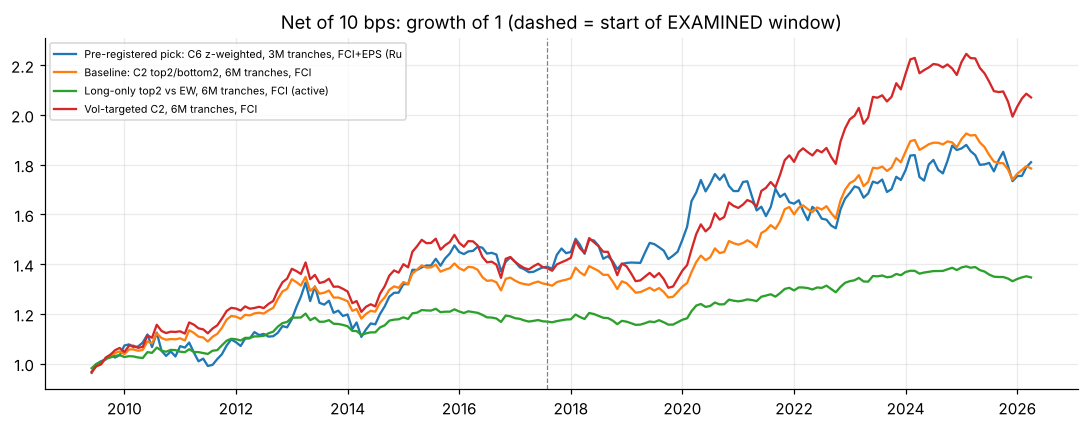

In [18]:
CANDS = {'Pre-registered pick: C6 z-weighted, 3M tranches, FCI+EPS (Rules P+S+E)': ('C6 LS z-weighted', '3M overlapping tranches', SE if RULE_E else S0),
         'Baseline: C2 top2/bottom2, 6M tranches, FCI': ('C2 LS top2-bottom2', '6M overlapping tranches', S0),
         'Long-only top2 vs EW, 6M tranches, FCI (active)': ('C4 LO top2', '6M overlapping tranches', S0),
         'Vol-targeted C2, 6M tranches, FCI': ('C9 LS top2-bottom2 vol-tgt', '6M overlapping tranches', S0)}
rows, perf_rows = [], []
for nm, (cname, sched, sig) in CANDS.items():
    sp = SCHEDULES[sched]; outs = [simulate(make_target(sig, cname), sp['H'], sp['step'], o, start=pd.Period('2009-05', 'M')) for o in sp['offsets']]
    g, tn, h = outs[0]; bench_ = EWG if is_lo(cname) else 0
    for b in RULES['costs']:
        for wl, w in WINDOWS.items():
            perf_rows.append({'approach': nm, 'cost bps': b, 'window': wl, **perf(g - tn * b * 1e-4 - bench_, None, 0, w), 'Turnover p.a. (x)': tn.loc[w[0]:w[1]].mean() * 12})
    net = (g - tn * 10e-4 - bench_).loc[FULL_R[0]:FULL_R[1]]
    P = ((h.shift(1) - (0.2 if is_lo(cname) else 0)) * R).loc[FULL_R[0]:FULL_R[1]]
    r = {'approach': nm, 'full Sharpe 10bps': net.mean() / net.std() * np.sqrt(12)}
    for c in COUNTRIES:
        x = net - P[c]; r[f'without {c} P&L'] = x.mean() / x.std() * np.sqrt(12)
    srt = net.sort_values(ascending=False)
    for k in (6, 12): x = srt.iloc[k:]; r[f'drop best {k} months'] = x.mean() / x.std() * np.sqrt(12)
    yr = net.groupby(net.index.year).sum(); r['years positive'] = f'{(yr > 0).sum()}/{len(yr)}'
    ac_ = [net.autocorr(k) for k in range(1, 12)]; r['Lo-adjusted Sharpe'] = (net.mean() / net.std()) * 12 / np.sqrt(12 + 2 * sum((12 - k) * ac_[k - 1] for k in range(1, 12)))
    r['block-boot p (L=12)'] = mbb_p(net.values)
    rows.append(r)
ROB = pd.DataFrame(rows).set_index('approach'); display(ROB.T.round(3)); ROB.to_csv(OUT/'robustness_candidates.csv')
CP = pd.DataFrame(perf_rows).set_index(['approach', 'cost bps', 'window']); CP.to_csv(OUT/'candidates_by_cost.csv')
show = CP['Sharpe'].unstack(['window']).round(2); display(show)
fig, ax = plt.subplots(figsize=(10, 4))
for nm, (cname, sched, sig) in CANDS.items():
    sp = SCHEDULES[sched]; g, tn, h = simulate(make_target(sig, cname), sp['H'], sp['step'], 0, start=pd.Period('2009-05', 'M'))
    n = (g - tn * 10e-4 - (EWG if is_lo(cname) else 0)).loc[FULL_R[0]:].fillna(0); ax.plot(n.index.to_timestamp(), (1 + n).cumprod(), label=nm[:60])
ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls='--', lw=.8); ax.set_title('Net of 10 bps: growth of 1 (dashed = start of EXAMINED window)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(CH/'candidates_net10.png', bbox_inches='tight'); plt.show()

## 9. Registry amendments and summary export

In [19]:
REG['amendments'] = AMEND; REG['outcomes'] = {'Rule P pick': ' | '.join(PICK_P), 'Rule S variants passing': PICK_S, 'Rule E add EPS': RULE_E,
                                              'walk-forward Sharpe 2013-2026 (10bps)': wfm['walk-forward 2013-2026']['Sharpe'],
                                              'max Sharpe any config any window at 0 bps': float(PC.xs(0, level='cost bps')['Sharpe'].max())}
json.dump(REG, open(OUT/'experiment_registry.json', 'w'), indent=2, default=str)
print(json.dumps(REG['outcomes'], indent=2, default=str))

{
  "Rule P pick": "C6 LS z-weighted | 3M overlapping tranches",
  "Rule S variants passing": [],
  "Rule E add EPS": true,
  "walk-forward Sharpe 2013-2026 (10bps)": 0.2190558131948101,
  "max Sharpe any config any window at 0 bps": 0.8147524441421466
}
